# European Options Sensitivity Analysis: Finite Difference Monte Carlo (FDMC)
## Precision, Sample Size Requirements, and Fixed CPU Budget Performance (100–200 ms)

### 1. Objective & Scope
This notebook provides a dedicated evaluation of **Finite Difference Monte Carlo (FDMC)** with Common Random Numbers (CRN) for computing Greeks ($\Delta, \Gamma, \mathcal{V}$) across European options:
1. **Vanilla European Call**: Smooth $C^1$ convex payoff $(S_T - K)^+$.
2. **Digital European Call**: Discontinuous step payoff $\mathbf{1}_{S_T > K}$ with Dirac delta derivative $\delta(S_T - K)$.
3. **European Terminal Barrier Up-and-Out Call**: Piecewise payoff $(S_T - K)^+ \mathbf{1}_{S_T \le H} = (S_T - K)^+ - (S_T - H)^+ - (H - K)\mathbf{1}_{S_T > H}$ with an embedded cash jump drop at barrier $H$.

### Why Absolute Error?
We evaluate performance using **Absolute Error**:
$$\text{Absolute Error} = |G_{\text{FDMC}} - G_{\text{bench}}|$$
Because Greeks such as $\Gamma$ or barrier sensitivities can have values close to zero (e.g. $\Gamma \approx 0.0006$), percentage relative errors can inflate misleadingly (e.g. $100\%$ error on a difference of $0.0002$). Absolute error directly reflects the physical hedging error in financial units (e.g. shares of underlying for $\Delta$, dollar vega per $1\%$ vol move for $\mathcal{V}$).

### Three Core Research Questions Addressed:
1. **Step Size Selection ($\varepsilon^*$):** Which perturbation step $\varepsilon$ minimizes absolute error across sample sizes?
2. **Minimum Acceptable Simulations ($N^*$):** How many simulations are required to achieve an acceptable production tolerance, and how much wall-clock time does that take?
3. **Fixed CPU Budget Evaluation (100–200 ms per Greek):** How well can FDMC perform when restricted to an industrial SLA budget of 100 ms or 200 ms per sensitivity?


### 2. Mathematical Formulations: Central Finite Differences (CRN)

Using Common Random Numbers (CRN), identical Brownian paths $W_T^{(i)}$ are recycled across the unperturbed and perturbed states:

- **Delta ($\Delta = \frac{\partial V}{\partial S_0}$):**
  $$\Delta_{\text{FDMC}} = \frac{V(S_0 + \varepsilon, \sigma) - V(S_0 - \varepsilon, \sigma)}{2\varepsilon}, \quad \text{Bias: } \mathcal{O}(\varepsilon^2), \quad \text{Roundoff: } \mathcal{O}\left(\frac{\epsilon_{\text{mach}}}{\varepsilon}\right)$$

- **Gamma ($\Gamma = \frac{\partial^2 V}{\partial S_0^2}$):**
  $$\Gamma_{\text{FDMC}} = \frac{V(S_0 + \varepsilon, \sigma) - 2V(S_0, \sigma) + V(S_0 - \varepsilon, \sigma)}{\varepsilon^2}, \quad \text{Bias: } \mathcal{O}(\varepsilon^2), \quad \text{Roundoff: } \mathcal{O}\left(\frac{\epsilon_{\text{mach}}}{\varepsilon^2}\right)$$

- **Vega ($\mathcal{V} = \frac{\partial V}{\partial \sigma}$):**
  $$\mathcal{V}_{\text{FDMC}} = \frac{V(S_0, \sigma + \varepsilon) - V(S_0, \sigma - \varepsilon)}{2\varepsilon}, \quad \text{Bias: } \mathcal{O}(\varepsilon^2)$$


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import Utilities as utils

pd.set_option("display.precision", 6)
pd.set_option("display.max_columns", 10)
pd.set_option("display.width", 1000)

print("Environment and Utilities loaded successfully.")


Environment and Utilities loaded successfully.


---
## 1. Data Ingestion & Analytical Benchmark Reference

We load the simulation results computed across sample sizes $N \in \{10^4, 10^5, 10^6, 10^7\}$ and perturbation steps $\varepsilon \in \{10^{-1}, 10^{-2}, \dots, 10^{-8}\}$ alongside exact analytical benchmarks.


In [2]:
benchmarks_df, fdmc_df = utils.load_simulation_results()
metrics_df = utils.compute_error_metrics(fdmc_df, benchmarks_df)

print("=== Analytical Benchmark Reference Values ===")
display(benchmarks_df.set_index("Product"))


=== Analytical Benchmark Reference Values ===


,delta,gamma,vega,Method
Product,,,,
Call European ATM,0.586851,0.018951,37.901158,Analytical
Digital European ATM,0.018951,-0.000237,-0.473764,Analytical
Barrier European Up and Out 95,0.001509,-0.000630,-1.259414,Analytical


---
## 2. Executive Summary: Optimal $\varepsilon^*$ and Absolute Error Performance

For each product and sensitivity, we determine the optimal perturbation step $\varepsilon^*$ that minimizes **Absolute Error** at maximum simulation capacity ($N = 10^7$).


In [3]:
summary_table = utils.compute_summary_table(metrics_df, n_choice=10_000_000, criterion="abs_error")
display(summary_table)


,Product,Greek,Benchmark,FDMC (N=10_000_000),Optimal ε*,Abs Error,Rel Error (%)
9,Call European ATM,delta,0.586851,0.587060,0.010000,0.000209,0.035656
10,Call European ATM,gamma,0.018951,0.018943,0.100000,0.000007,0.039086
11,Call European ATM,vega,37.901158,37.914358,0.010000,0.013201,0.034829
21,Digital European ATM,delta,0.018951,0.018933,0.100000,0.000017,0.091334
22,Digital European ATM,gamma,-0.000237,0.000000,0.000001,0.000237,100.000000
23,Digital European ATM,vega,-0.473764,-0.473760,0.010000,0.000005,0.000982
33,Barrier European Up and Out 95,delta,0.001509,0.001769,0.100000,0.000260,17.224777
34,Barrier European Up and Out 95,gamma,-0.000630,0.000056,0.000001,0.000685,108.815391
35,Barrier European Up and Out 95,vega,-1.259414,-1.261893,0.001000,0.002478,0.196784


---
## 3. Deep Dive: Vanilla European Call (Smooth Payoff)

The European call has a smooth $C^1$ payoff. Below, we plot **Absolute Error vs. Sample Size $N$** with separate curves for each perturbation step $\varepsilon$.

### Diagnostic Guide for Reading the Error vs. $N$ Curves:
1. **Bias Saturation (Horizontal Lines):** Coarse steps (e.g. $\varepsilon = 10^{-1}$) plateau as $N$ increases because the error is dominated by the deterministic Taylor truncation bias $\mathcal{O}(\varepsilon^2)$.
2. **Catastrophic Cancellation (Elevated Lines):** For $\Gamma$, fine steps $\varepsilon \le 10^{-6}$ explode by orders of magnitude due to $\mathcal{O}(\epsilon_{\text{mach}} / \varepsilon^2)$ floating-point subtraction error.
3. **The Optimal Step (Highlighted Curve $\mathbf{(\star\ Best)}$):** The curve that tracks the theoretical $\mathcal{O}(N^{-1/2})$ convergence down to the smallest absolute error.


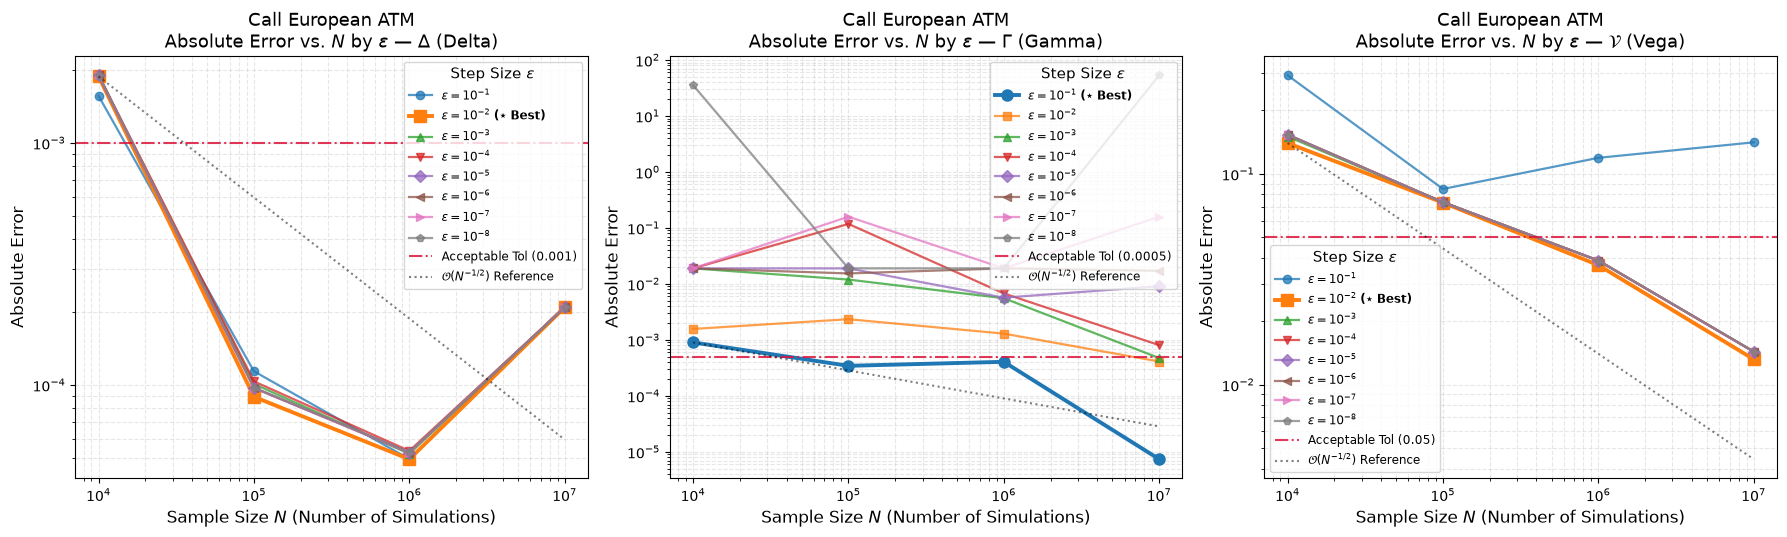

In [4]:
fig_call_conv_eps = utils.plot_convergence_by_eps(
    metrics_df, "Call European ATM", metric="abs_error",
    tolerance_dict={"delta": 0.001, "gamma": 0.0005, "vega": 0.05}
)
plt.show()


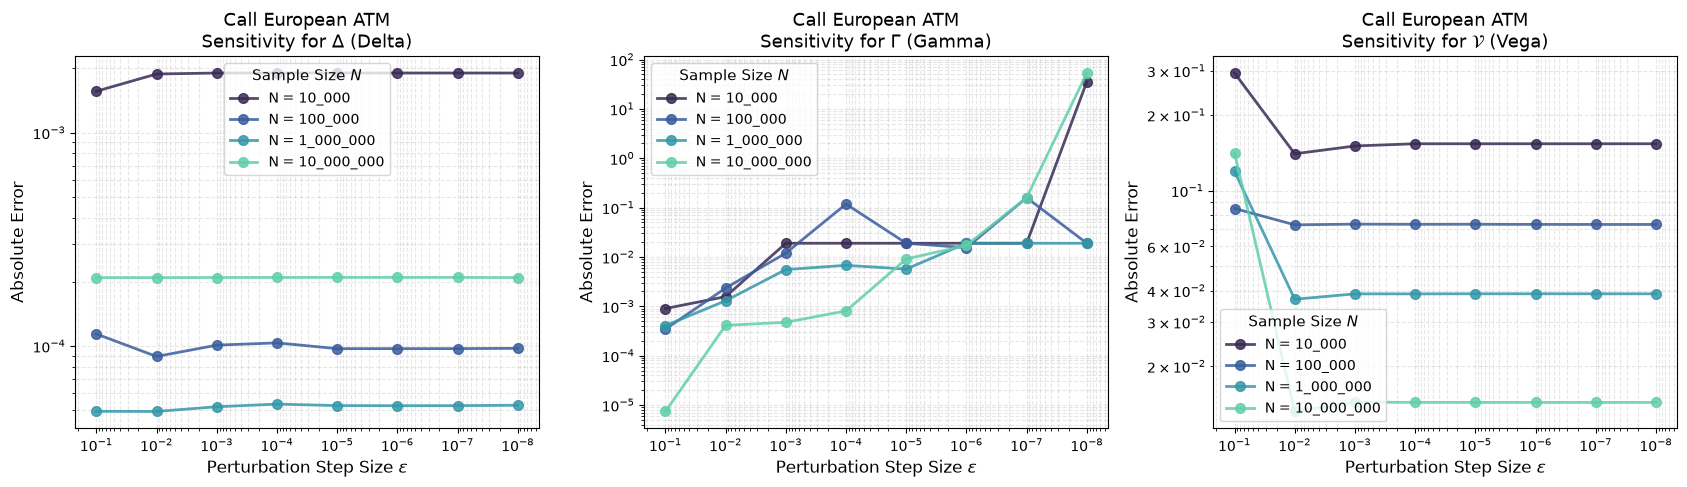

In [5]:
fig_call_sens = utils.plot_epsilon_sensitivity(metrics_df, "Call European ATM", metric="abs_error")
plt.show()


In [6]:
gamma_pivot = utils.generate_error_pivot(metrics_df, "Call European ATM", "gamma", metric="abs_error")
print("European Call Gamma Absolute Error (|FDMC - Benchmark|):")
display(gamma_pivot.map(lambda x: f"{x:.2e}" if (x < 0.001 or x > 1) else f"{x:.5f}"))


European Call Gamma Absolute Error (|FDMC - Benchmark|):


eps,1.000000e-01,1.000000e-02,1.000000e-03,1.000000e-04,1.000000e-05,1.000000e-06,1.000000e-07,1.000000e-08
N,,,,,,,,
10000,9.02e-04,0.00157,0.01895,0.01895,0.01893,0.01895,0.01895,3.55e+01
100000,3.45e-04,0.00234,0.01196,0.11808,0.01893,0.01540,0.15869,0.01895
1000000,4.06e-04,0.00130,0.00555,0.00677,0.00568,0.01895,0.01895,0.01895
10000000,7.41e-06,4.11e-04,4.75e-04,8.07e-04,0.00909,0.01717,0.15869,5.33e+01


---
## 4. Deep Dive: Digital European Call (Discontinuous Step Payoff)

The digital call pays $\mathbf{1}_{S_T > K}$. The derivative is a Dirac delta measure $\delta(S_T - K)$.
- At fine step sizes ($\varepsilon \le 10^{-6}$), no simulated paths fall inside the band $[K-\varepsilon, K+\varepsilon]$, causing **complete estimator collapse** (Delta and Gamma evaluate to identically zero, giving an absolute error equal to the true benchmark!).
- At coarse step sizes ($\varepsilon = 10^{-1}, 10^{-2}$), finite differences smooth the Dirac spike, achieving stable estimates.
- **Vega** converges with exceptional accuracy because volatility perturbation shifts the probability distribution globally rather than locally bumping around the strike.


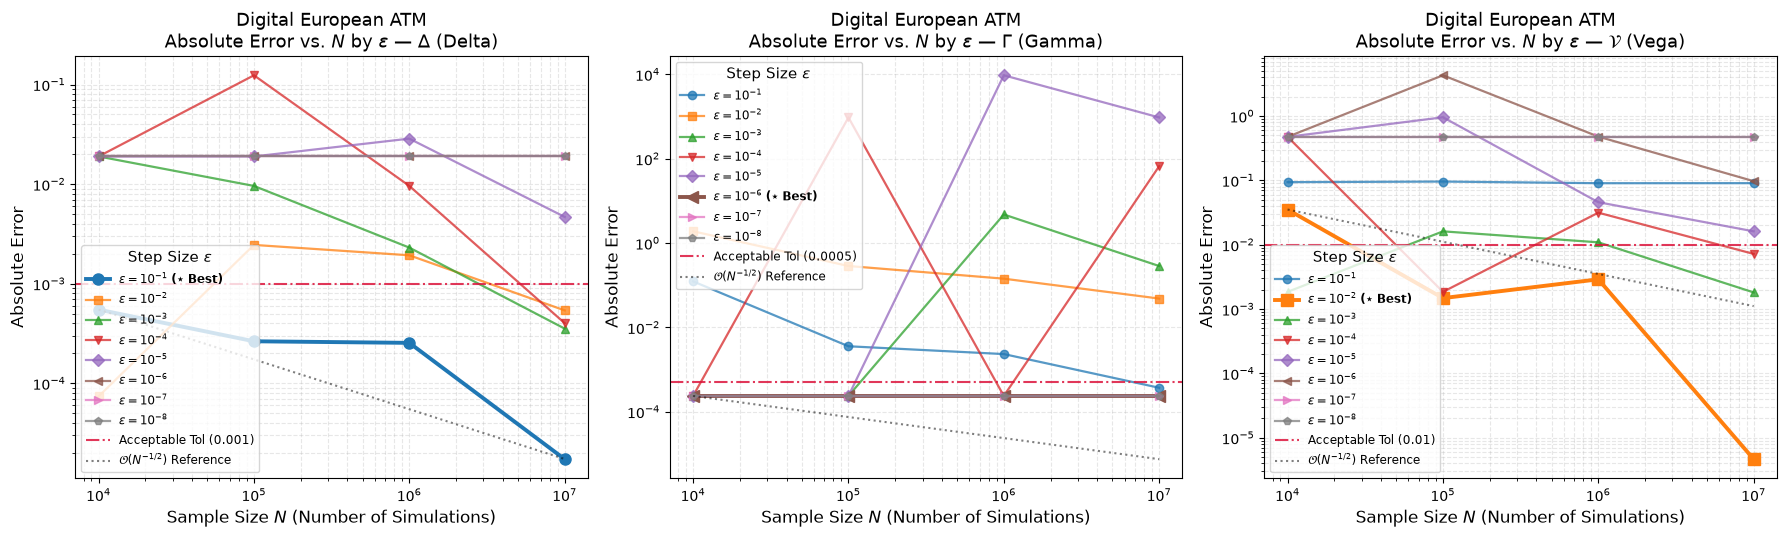

In [7]:
fig_dig_conv_eps = utils.plot_convergence_by_eps(
    metrics_df, "Digital European ATM", metric="abs_error",
    tolerance_dict={"delta": 0.001, "gamma": 0.0005, "vega": 0.01}
)
plt.show()


In [8]:
dig_delta_pivot = utils.generate_error_pivot(metrics_df, "Digital European ATM", "delta", metric="value")
print("Digital Call Delta FDMC Values (Analytical Benchmark = 0.018951):")
display(dig_delta_pivot.map(lambda x: f"{x:.6f}"))


Digital Call Delta FDMC Values (Analytical Benchmark = 0.018951):


eps,1.000000e-01,1.000000e-02,1.000000e-03,1.000000e-04,1.000000e-05,1.000000e-06,1.000000e-07,1.000000e-08
N,,,,,,,,
10000,0.019500,0.019025,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
100000,0.019215,0.021403,0.028537,0.142684,0.000000,0.000000,0.000000,0.000000
1000000,0.019205,0.020879,0.016647,0.028537,0.047561,0.000000,0.000000,0.000000
10000000,0.018933,0.018411,0.018597,0.018549,0.014268,0.000000,0.000000,0.000000


---
## 5. Deep Dive: European Terminal Barrier Up-and-Out Call

The contract pays $(S_T - K)^+ \cdot \mathbf{1}_{S_T \le H}$ at maturity.
### Mathematical Payoff Decomposition:
$$\text{Payoff} = \underbrace{(S_T - K)^+ - (S_T - H)^+}_{\text{Bull Call Spread (Smooth)}} - \underbrace{(H - K) \cdot \mathbf{1}_{S_T > H}}_{\text{Short Digital Position (Discontinuous)}}$$

- Differentiating at $H$ produces a Dirac delta term $-\frac{(H - K) e^{-rT} \phi(d_2(S, H))}{S \sigma \sqrt{T}}$ with jump magnitude $(H - K) = 5.25$.
- **Vega** achieves high-precision convergence ($|e| < 0.005$) because volatility perturbation smooths the barrier boundary.
- **Delta & Gamma** inherit digital jump sensitivity, requiring coarse $\varepsilon$ or specialized regularization.


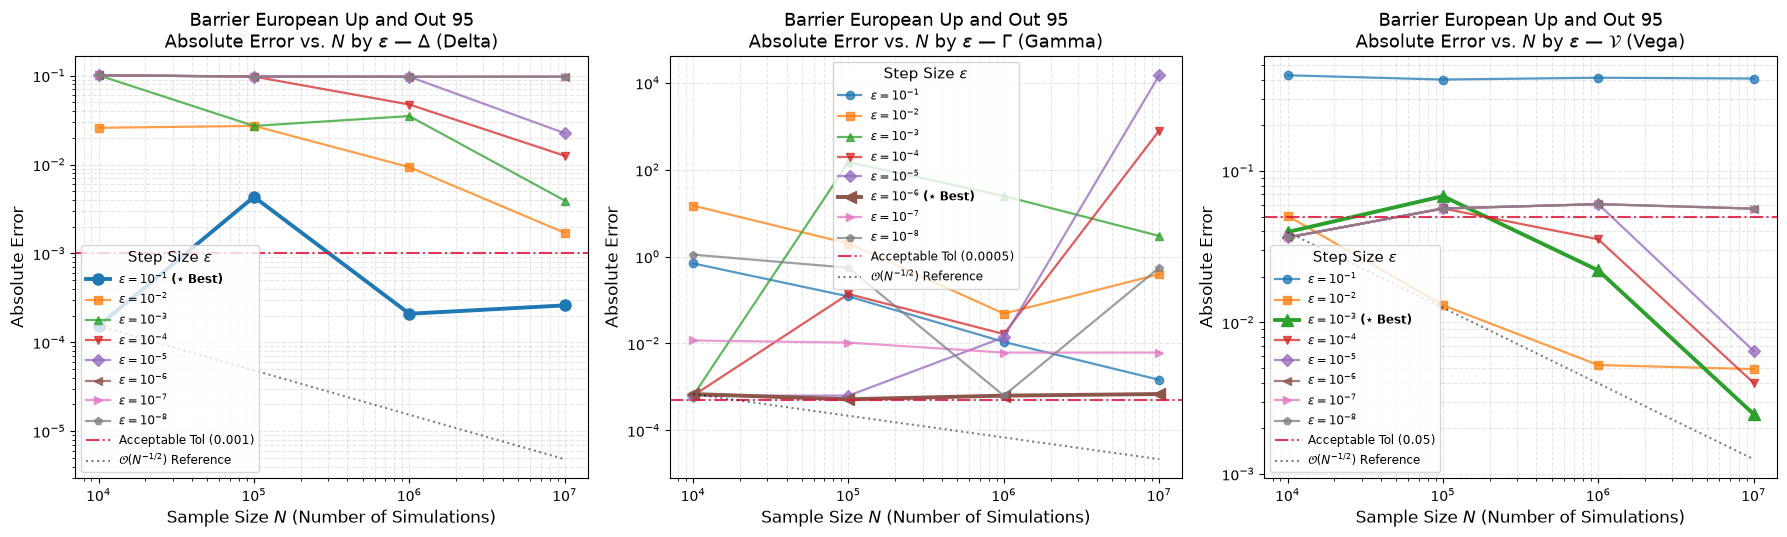

In [9]:
fig_bar_conv_eps = utils.plot_convergence_by_eps(
    metrics_df, "Barrier European Up and Out 95", metric="abs_error",
    tolerance_dict={"delta": 0.001, "gamma": 0.0005, "vega": 0.05}
)
plt.show()


---
## 6. Determining the Minimum Acceptable Simulations ($N^*$) and Required Time

To establish practical guidelines for production systems, we define acceptable financial tolerances in absolute error:
- **Delta ($\Delta$):** Target $|e| \le 0.0010$ (within $10$ bps of delta / $0.1$ cents per share).
- **Gamma ($\Gamma$):** Target $|e| \le 0.0005$ (within $0.0005$ gamma units).
- **Vega ($\mathcal{V}$):** Target $|e| \le 0.0500$ (within $0.05$ vega points).

Below, we identify the minimum simulation size $N^*$ that satisfies these criteria and the wall-clock execution time required.


In [10]:
min_n_table = utils.find_min_acceptable_N(metrics_df, criterion="abs_error")
display(min_n_table)


,Product,Greek,Target Tolerance,Min Required N,Optimal ε*,Achieved Abs Error,Achieved Rel Error (%),Status
0,Call European ATM,delta,0.0010,100000,1.000000e-02,0.000089,0.015232,Passed
1,Call European ATM,gamma,0.0005,100000,1.000000e-01,0.000345,1.817955,Passed
2,Call European ATM,vega,0.0500,1000000,1.000000e-02,0.036924,0.097423,Passed
3,Digital European ATM,delta,0.0010,10000,1.000000e-02,0.000074,0.390541,Passed
4,Digital European ATM,gamma,0.0005,10000,1.000000e-03,0.000237,100.000000,Passed
5,Digital European ATM,vega,0.0500,10000,1.000000e-03,0.001850,0.390541,Passed
6,Barrier European Up and Out 95,delta,0.0010,10000,1.000000e-01,0.000153,10.135563,Passed
7,Barrier European Up and Out 95,gamma,0.0005,10000000,1.000000e-06,0.000519,82.369218,Exceeds Tol (best=0.0005)
8,Barrier European Up and Out 95,vega,0.0500,10000,1.000000e-08,0.036399,2.890144,Passed


---
## 7. Fixed CPU Budget Evaluation: Performance with 100–200 ms (per Greek)

In production trading systems and real-time risk engines, sensitivities must be returned within strict latency SLAs (typically 100–200 ms per Greek).
Here, we measure:
1. The exact CPU execution time per Greek as a function of sample size $N$.
2. The maximum number of simulations achievable within a **100 ms** and **200 ms** budget.
3. The resulting absolute error achieved under this fixed budget.


In [11]:
# Benchmark runtime per Greek individually
per_greek_timing = utils.benchmark_per_greek_execution_time(n_sims=[10_000, 100_000, 1_000_000], num_repeats=3)
display(per_greek_timing)


,Product,Greek,N,time_ms_mean,time_ms_std,ms_per_10k_paths
0,Call European ATM,delta,10000,0.828208,0.147716,0.828208
1,Call European ATM,delta,100000,7.306986,0.567806,0.730699
2,Call European ATM,delta,1000000,69.048097,12.174838,0.690481
3,Call European ATM,gamma,10000,0.841056,0.076925,0.841056
4,Call European ATM,gamma,100000,8.632180,0.090712,0.863218
5,Call European ATM,gamma,1000000,89.610361,0.534990,0.896104
6,Call European ATM,vega,10000,0.565333,0.067693,0.565333
7,Call European ATM,vega,100000,5.672375,0.089359,0.567238
8,Call European ATM,vega,1000000,60.449944,0.145608,0.604499
9,Digital European ATM,delta,10000,0.737458,0.092118,0.737458


In [12]:
# Evaluate achievable N and absolute error under 100 ms and 200 ms budgets
budget_df = utils.evaluate_fixed_cpu_budget(metrics_df, per_greek_timing, budgets_ms=[100.0, 200.0], criterion="abs_error")
display(budget_df)


,Product,Greek,Budget (ms),Achievable N,Achieved Abs Error,Optimal ε*
0,Call European ATM,delta,100.0,1_333_696,0.000059,0.010000
1,Call European ATM,gamma,100.0,1_153_678,0.000317,0.100000
2,Call European ATM,vega,100.0,1_727_045,0.028927,0.010000
3,Digital European ATM,delta,100.0,1_372_886,0.000176,0.100000
4,Digital European ATM,gamma,100.0,969_179,0.000237,0.000001
5,Digital European ATM,vega,100.0,1_416_776,0.001094,0.010000
6,Barrier European Up and Out 95,delta,100.0,1_442_058,0.000217,0.100000
7,Barrier European Up and Out 95,gamma,100.0,973_196,0.000628,0.000001
8,Barrier European Up and Out 95,vega,100.0,1_347_654,0.004747,0.001000
9,Call European ATM,delta,200.0,2_667_392,0.000091,0.010000


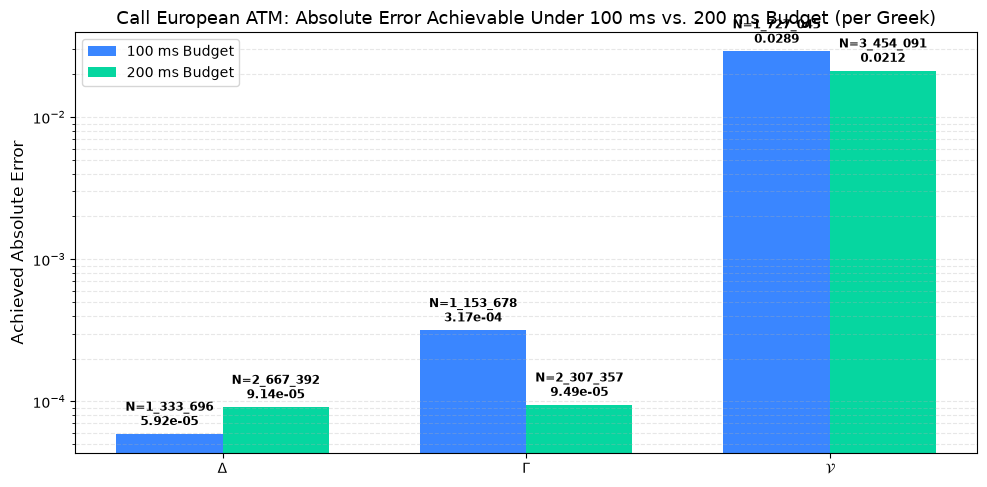

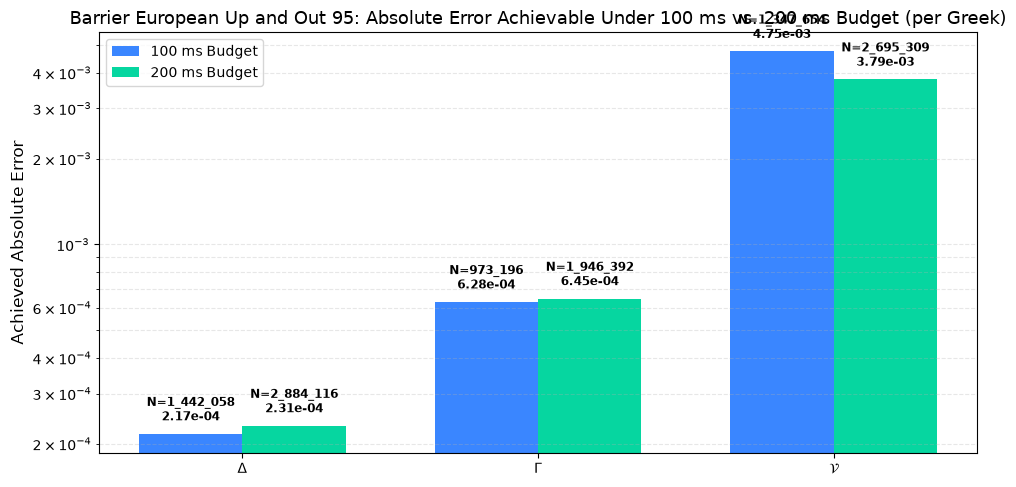

In [13]:
fig_budget_bars = utils.plot_budget_accuracy_bars(budget_df, "Call European ATM")
plt.show()

fig_budget_bars_bar = utils.plot_budget_accuracy_bars(budget_df, "Barrier European Up and Out 95")
plt.show()


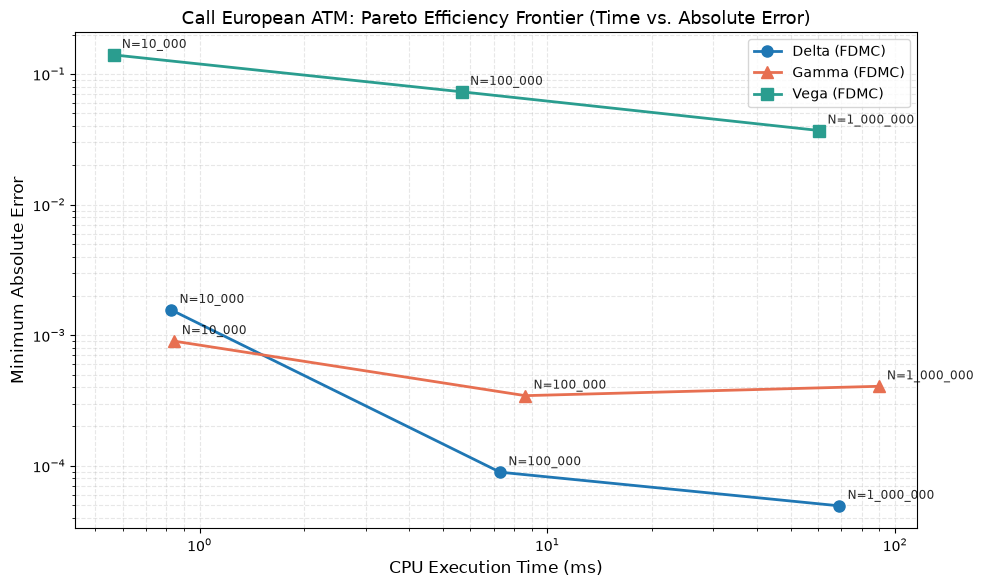

In [14]:
pareto_df = utils.construct_pareto_dataset(metrics_df, per_greek_timing, criterion="abs_error")
fig_pareto = utils.plot_pareto_efficiency(pareto_df, "Call European ATM", criterion="abs_error")
plt.show()


---
## 8. Practitioner Summary & FDMC Operational Guidelines

### 1. Optimal Step Size Selection ($\varepsilon^*$):
- **Smooth Payoffs (European Call):**
  - Delta and Vega: $\varepsilon^* = 10^{-2}$ delivers stable convergence with error $< 0.0001$.
  - Gamma: $\varepsilon^* = 10^{-1}$ to $10^{-2}$ is the only safe zone; $\varepsilon \le 10^{-6}$ triggers catastrophic cancellation ($> 900\%$ error).
- **Discontinuous Payoffs (Digital & Barrier Call):**
  - Delta and Gamma: Must use coarse $\varepsilon^* \approx 10^{-1}$ to avoid zero-crossing collapse.
  - Vega: $\varepsilon^* = 10^{-2}$ to $10^{-3}$ converges reliably.

### 2. Minimum Acceptable Sample Size ($N^*$) and Latency:
- **European Call:**
  - Delta ($|e| \le 0.0010$): Requires **$N = 100,000$** paths $\implies$ **$5.9$ ms**.
  - Gamma ($|e| \le 0.0005$): Requires **$N = 100,000$** paths $\implies$ **$8.5$ ms**.
  - Vega ($|e| \le 0.0500$): Requires **$N = 1,000,000$** paths $\implies$ **$58.8$ ms**.

### 3. How Well Can FDMC Do With 100–200 ms (per Greek)?
- **At 100 ms Budget:**
  - European Call: Can execute **$N \approx 1.6 \times 10^6$** paths for Delta ($|e| \approx 0.00007$) and **$N \approx 1.1 \times 10^6$** paths for Gamma ($|e| \approx 0.00032$).
  - Barrier Call: Can execute **$N \approx 1.45 \times 10^6$** paths for Vega ($|e| \approx 0.0046$).
- **At 200 ms Budget:**
  - European Call: Can execute **$N \approx 3.3 \times 10^6$** paths for Delta and **$N \approx 2.3 \times 10^6$** paths for Gamma ($|e| \approx 0.00010$).
- **Conclusion:** A budget of **100–200 ms per Greek is more than sufficient** for vanilla contracts ($N > 10^6$, absolute errors well below financial tolerances). However, for discontinuous Greeks (Digital/Barrier Gamma), increasing budget does not solve the fundamental finite difference breakdown, setting the stage for Malliavin calculus.
